# Integrative Assay Summary

In [1]:
import sys
import polars as pl
import pandas as pd
import numpy as np
# Create heatmap with custom colors
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedFormatter

sys.path.append("../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../../2_individual_assay_results")
from analyses_plot_utils import *

## 1. Loading data

### 1.1 Clean up allele collection

In [2]:
# ALLELE_COLLECTION_INFO = "../../1_allele_collection/3_outputs"
# clin_var_df = pl.read_csv(f"{ALLELE_COLLECTION_INFO}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv", 
#                           separator="\t", infer_schema_length=10000
# ).with_columns(
#     pl.col("symbol").str.replace_all(r"[^a-zA-Z0-9]", "").alias("symbol"),
#     pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
#     pl.col("rsa").cast(pl.Float32).alias("rsa_f32")
# ).with_columns(
#     (
#         pl.when(pl.col("rsa_f32")<.1)
#         .then(pl.lit("<10"))
#         .when(pl.col("rsa_f32")>=.9)
#         .then(pl.lit("$\geqslant$90"))
#         .otherwise(pl.lit("10-90"))
#     ).alias("RSA_Category"),
#     (
#         pl.when(pl.col("plddt_f32")<=50)
#         .then(pl.lit("<=50"))
#         .when((pl.col("plddt_f32")>50)&(pl.col("plddt_f32")<=70))
#         .then(pl.lit("50-70"))
#         .when((pl.col("plddt_f32")>70)&(pl.col("plddt_f32")<=90))
#         .then(pl.lit("70-90"))
#         .otherwise(pl.lit(">90"))
#     ).alias("pLDDT_Category")
# )
# clin_var_df.write_csv("../1_inputs/varchamp_clinvar_gnomad_dbnsfp_disease_modules.tsv", separator="\t")

### 1.2 Merge allele collection with DUAL-IPA, Imaging and PPI assays

In [3]:
dualipa_outputs = "../../2_individual_assay_results/dual_ipa/3_outputs"
imaging_outputs = "../../2_individual_assay_results/imaging/3_outputs"
ppi_outputs = "../../2_individual_assay_results/ppi/3_outputs/sqY2H"

allele_col_df = pl.read_csv(f"../../1_allele_collection/3_outputs/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI.tsv", 
                            separator="\t", infer_schema_length=100000).with_columns(
                                pl.col("clinvar_clnsig_clean").replace("6_No_ClinVar", "5_Others")
                            )
dualipa = pl.read_csv(f"{dualipa_outputs}/annotated_perturbation_scores.csv", infer_schema_length=100000)
print("DUAL-IPA:", dualipa.shape[0], dualipa.unique(subset="gene_variant").shape[0])
imaging = pl.read_csv(f"{imaging_outputs}/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
print("Imaging:", imaging.shape[0], imaging.unique(subset="gene_allele").shape[0])
ppi = pl.read_csv(f"{ppi_outputs}/orf_distances_final.csv", infer_schema_length=100000)
ppi = ppi.rename({"db_orf_id": "orf_id", "db_mut_id": "mut_id"})
print("PPI:", ppi.shape[0], ppi.unique(subset="gene_variant").shape[0])

DUAL-IPA: 804 804
Imaging: 859 859
PPI: 511 511


In [9]:
al_dual_df = allele_col_df.with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id")
).join(
    dualipa.select(["orf_id", "mut_id"]+[c for c in dualipa.columns if c not in allele_col_df.columns]),
    left_on=["orf_id", "mut_id"],
    right_on=["orf_id", "mut_id"],
    how="left"
)

al_dual_ppi = al_dual_df.join(
    ppi.select(["orf_id", "mut_id"]+[c for c in ppi.columns if c not in allele_col_df.columns]),
    left_on=["orf_id", "mut_id"],
    right_on=["orf_id", "mut_id"],
    how="left",
    suffix="_ppi"
)

al_dual_img_ppi = al_dual_ppi.join(
    imaging.select([c for c in imaging.columns if c not in allele_col_df.columns]),
    left_on="gene_variant",
    right_on="gene_allele",
    how="left",
    suffix="_img"
)

al_dual_img_ppi
al_dual_img_ppi.to_pandas().drop_duplicates(subset=["gene_variant"])

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,seq,...,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,AUROC_BioRep2_GFP_ADJ
0,GBA1,ENSG00000177628,2,6,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,ATGGAGTTTTCAAGTCCTTCCAGAGAGGAATGTCCCAAGCCTTTGA...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,GBA1,ENSG00000177628,2,73,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,ATGGAGTTTTCAAGTCCTTCCAGAGAGGAATGTCCCAAGCCTTTGA...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GBA1,ENSG00000177628,2,113,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,ATGGAGTTTTCAAGTCCTTCCAGAGAGGAATGTCCCAAGCCTTTGA...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,GBA1,ENSG00000177628,2,231,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,ATGGAGTTTTCAAGTCCTTCCAGAGAGGAATGTCCCAAGCCTTTGA...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,GBA1,ENSG00000177628,2,213510,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,ATGGAGTTTTCAAGTCCTTCCAGAGAGGAATGTCCCAAGCCTTTGA...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9594,ZC4H2,None,4320,0,CCSBVarC009188,None,NC_000023.11:64921845:A:T,197T>A,Leu66His,ATGGCAGATGAGCAAGAAATCATGTGCAAATTGGAAAGCATTAAAG...,...,0.702777,0.852130,0.980189,0.983614,0.953026,0.840882,0.895706,0.872323,0.983878,0.982826
9595,ZC4H2,None,4320,0,CCSBVarC009191,None,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,ATGGCAGATGAGCAAGAAATCATGTGCAAATTGGAAAGCATTAAAG...,...,0.688109,0.519651,0.886473,0.878921,0.797544,0.715681,0.786635,0.626973,0.935876,0.934480
9596,ZC4H2,None,4320,0,CCSBVarC009194,None,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,ATGGCAGATGAGCAAGAAATCATGTGCAAATTGGAAAGCATTAAAG...,...,0.798256,0.756840,0.964404,0.961241,0.645819,0.826481,0.756327,0.575189,0.978935,0.973651
9597,ZC4H2,None,4320,0,CCSBVarC009197,None,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,ATGGCAGATGAGCAAGAAATCATGTGCAAATTGGAAAGCATTAAAG...,...,0.681873,0.618429,0.789327,0.743271,0.752382,0.661837,0.662699,0.686541,0.930693,0.914256


In [6]:
print(al_dual_img_ppi.drop_nulls("dualipa_abun_score").shape)
print(al_dual_img_ppi.drop_nulls("AUROC_Mean_GFP").shape) ## Duplicated gene_variants
print(al_dual_img_ppi.drop_nulls("normalized_euclid_distance_normalized").shape)

(846, 1083)
(1047, 1083)
(547, 1083)


In [10]:
al_dual_img_ppi_assayed = al_dual_img_ppi.filter(
    pl.col("dualipa_abun_score").is_not_null()
    | pl.col("AUROC_Mean_GFP").is_not_null()
    | pl.col("normalized_euclid_distance_normalized").is_not_null()
)

display(
    al_dual_img_ppi_assayed.unique(
        "gene_variant"
    ).group_by("clinvar_clnsig_clean_pp_strict").agg(
        pl.len().alias("n_variants"),
    ).sort("clinvar_clnsig_clean_pp_strict")
)

clinvar_clnsig_clean_pp_strict,n_variants
str,u32
"""Benign""",68
"""Conflicting""",230
"""Likely benign""",96
"""Likely pathogenic""",268
"""Others""",141
"""Pathogenic""",422
"""VUS""",212


In [14]:
vus = al_dual_img_ppi.filter(
    (pl.col("dualipa_abun_score").is_not_null()
    | pl.col("AUROC_Mean_GFP").is_not_null()
    | pl.col("normalized_euclid_distance_normalized").is_not_null()) &
    (pl.col("clinvar_clnsig_clean_pp_strict") == "VUS")
).unique(subset=["gene_variant"])

vus.group_by("symbol").agg(
    pl.len().alias("num_VUS")
).sort("num_VUS", descending=True).write_csv("../3_outputs/vus_per_gene.csv", separator=",")

vus_detailed = vus.with_columns(
    pl.col("dualipa_abun_score").is_not_null().alias("tested_DUAL-IPA"),
    pl.col("AUROC_Mean_GFP").is_not_null().alias("tested_Imaging"),
    pl.col("normalized_euclid_distance_normalized").is_not_null().alias("tested_PPI"),
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("hit_DUAL-IPA"),
    pl.when(pl.col("Altered_95th_perc_both_batches_GFP"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("hit_Imaging"),
    pl.col("ppi_hit").alias("hit_PPI")
).select([
    "symbol",
    "gene_variant",
    "nt_change",
    "aa_change",
    "spdi",
    "tested_DUAL-IPA",
    "tested_Imaging", 
    "tested_PPI",
    "hit_DUAL-IPA",
    "hit_Imaging",
    "hit_PPI",
    "dualipa_abun_score",
    "AUROC_Mean_GFP",
    "normalized_euclid_distance_normalized"
]).sort("symbol", "gene_variant")

# Save detailed VUS table
vus_detailed.write_csv("../3_outputs/vus_detailed_with_assays.csv")

# Also create a summary per gene
vus_gene_summary = vus_detailed.group_by("symbol").agg([
    pl.len().alias("num_VUS"),
    pl.col("tested_DUAL-IPA").sum().alias("tested_DUAL-IPA"),
    pl.col("tested_Imaging").sum().alias("tested_Imaging"),
    pl.col("tested_PPI").sum().alias("tested_PPI"),
    pl.col("hit_DUAL-IPA").sum().alias("hit_DUAL-IPA"),
    pl.col("hit_Imaging").sum().alias("hit_Imaging"),
    pl.col("hit_PPI").sum().alias("hit_PPI")
]).with_columns([
    (pl.col("hit_DUAL-IPA") / pl.col("tested_DUAL-IPA") * 100).round(1).alias("hit_rate_DUAL-IPA_%"),
    (pl.col("hit_Imaging") / pl.col("tested_Imaging") * 100).round(1).alias("hit_rate_Imaging_%"),
    (pl.col("hit_PPI") / pl.col("tested_PPI") * 100).round(1).alias("hit_rate_PPI_%")
]).sort("num_VUS", descending=True)

vus_gene_summary.write_csv("../3_outputs/vus_per_gene_with_assay_summary.csv")

# Display both tables
print("VUS Detailed Table (first 10 rows):")
display(vus_detailed.head(10))

print("\nVUS Gene Summary Table:")
display(vus_gene_summary)
vus_detailed

VUS Detailed Table (first 10 rows):


symbol,gene_variant,nt_change,aa_change,spdi,tested_DUAL-IPA,tested_Imaging,tested_PPI,hit_DUAL-IPA,hit_Imaging,hit_PPI,dualipa_abun_score,AUROC_Mean_GFP,normalized_euclid_distance_normalized
str,str,str,str,str,bool,bool,bool,bool,bool,bool,f64,f64,f64
"""ACSF3""","""ACSF3_Asp457Asn""","""1369G>A""","""Asp457Asn""","""NC_000016.10:89145269:G:A""",true,false,true,false,false,false,-1.223509,null,0.623782
"""ACSF3""","""ACSF3_Gly119Asp""","""356G>A""","""Gly119Asp""","""NC_000016.10:89101037:G:A""",true,false,true,false,false,false,-0.72648,null,0.614814
"""ACSF3""","""ACSF3_Gly225Arg""","""673G>A""","""Gly225Arg""","""NC_000016.10:89102610:G:A""",true,false,false,false,false,null,-1.094508,null,null
"""ACSF3""","""ACSF3_Met266Val""","""796A>G""","""Met266Val""","""NC_000016.10:89102733:A:G""",true,false,false,false,false,null,-0.323287,null,null
"""ACSF3""","""ACSF3_Ser431Tyr""","""1292C>A""","""Ser431Tyr""","""NC_000016.10:89133188:C:A""",true,false,false,true,false,null,-8.757981,null,null
"""ACSF3""","""ACSF3_Thr358Ile""","""1073C>T""","""Thr358Ile""","""NC_000016.10:89114434:C:T""",true,false,true,false,false,false,-0.831774,null,0.222027
"""AGXT""","""AGXT_Arg289Cys""","""865C>T""","""Arg289Cys""","""NC_000002.12:240877555:C:T""",true,false,true,false,false,false,-1.54984,null,0.527341
"""AGXT""","""AGXT_Arg301Cys""","""901C>T""","""Arg301Cys""","""NC_000002.12:240877591:C:T""",true,true,true,false,false,false,-0.214783,0.589519,0.533256
"""AGXT""","""AGXT_Asp129His""","""385G>C""","""Asp129His""","""NC_000002.12:240870670:G:C""",true,true,true,false,false,false,-0.317929,0.639608,0.177747



VUS Gene Summary Table:


symbol,num_VUS,tested_DUAL-IPA,tested_Imaging,tested_PPI,hit_DUAL-IPA,hit_Imaging,hit_PPI,hit_rate_DUAL-IPA_%,hit_rate_Imaging_%,hit_rate_PPI_%
str,u32,u32,u32,u32,u32,u32,u32,f64,f64,f64
"""SMAD3""",31,29,10,8,6,4,3,20.7,40.0,37.5
"""PKP2""",16,16,0,3,3,0,0,18.8,NaN,0.0
"""DES""",15,0,15,0,0,0,0,NaN,0.0,NaN
"""LITAF""",14,0,11,13,0,6,0,NaN,54.5,0.0
"""KCNJ2""",13,11,0,4,6,0,4,54.5,NaN,100.0
…,…,…,…,…,…,…,…,…,…,…
"""CFP""",1,1,0,0,0,0,0,0.0,NaN,NaN
"""TUFM""",1,1,0,0,0,0,0,0.0,NaN,NaN
"""GALE""",1,1,1,1,0,0,0,0.0,0.0,0.0


symbol,gene_variant,nt_change,aa_change,spdi,tested_DUAL-IPA,tested_Imaging,tested_PPI,hit_DUAL-IPA,hit_Imaging,hit_PPI,dualipa_abun_score,AUROC_Mean_GFP,normalized_euclid_distance_normalized
str,str,str,str,str,bool,bool,bool,bool,bool,bool,f64,f64,f64
"""ACSF3""","""ACSF3_Asp457Asn""","""1369G>A""","""Asp457Asn""","""NC_000016.10:89145269:G:A""",true,false,true,false,false,false,-1.223509,null,0.623782
"""ACSF3""","""ACSF3_Gly119Asp""","""356G>A""","""Gly119Asp""","""NC_000016.10:89101037:G:A""",true,false,true,false,false,false,-0.72648,null,0.614814
"""ACSF3""","""ACSF3_Gly225Arg""","""673G>A""","""Gly225Arg""","""NC_000016.10:89102610:G:A""",true,false,false,false,false,null,-1.094508,null,null
"""ACSF3""","""ACSF3_Met266Val""","""796A>G""","""Met266Val""","""NC_000016.10:89102733:A:G""",true,false,false,false,false,null,-0.323287,null,null
"""ACSF3""","""ACSF3_Ser431Tyr""","""1292C>A""","""Ser431Tyr""","""NC_000016.10:89133188:C:A""",true,false,false,true,false,null,-8.757981,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""TTR""","""TTR_Ala129Val""","""386C>T""","""Ala129Val""","""NC_000018.10:31598617:C:T""",false,false,true,false,false,false,null,null,0.215304
"""TUFM""","""TUFM_Arg339Gln""","""1016G>A""","""Arg339Gln""","""NC_000016.10:28844008:C:T""",true,false,false,false,false,null,-1.145394,null,null
"""UBQLN2""","""UBQLN2_Pro509Ser""","""1525C>T""","""Pro509Ser""","""NC_000023.11:56565398:C:T""",false,true,true,false,false,false,null,0.511295,0.206004


In [12]:
al_dual_img_ppi.filter(
    pl.col("dualipa_abun_score").is_not_null()
    | pl.col("AUROC_Mean_GFP").is_not_null()
    | pl.col("ppi_score_final_euclidean").is_not_null()
).with_columns(
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("dualipa_hit"),
    pl.when(pl.col("Altered_95th_perc_both_batches_GFP"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("imaging_hit")
).select(
    "symbol",
    "gene_variant",
    "clinvar_clnsig_clean",
    "dualipa_abun_score",
    "AUROC_Mean_GFP",
    "ppi_score_final_euclidean",
    "dualipa_hit",
    "imaging_hit",
    "ppi_hit"
).sort(
    "gene_variant"
).write_csv("../3_outputs/all_assay_gene_variant_summary.csv")

## 2. Plot Gene-level Summary per Assay

In [7]:
# def explained_gene_per_assay(assay_df, benign_thres=5.0, pathogenic_thres=20.0):
#     """
#     Analyze gene-level performance in functional assays with classification.
    
#     Returns all genes with hit percentages and classification based on thresholds.
#     """
    
#     df = plot_gene_level_summary(
#         assay_df, 
#         assay="assay_hit", 
#         cat="clinvar_clnsig_clean", 
#         palette=palette_dict["clinvar_clnsig_clean"]
#     )
    
#     # Create pivot table to get hit percentages by gene and clinvar category
#     gene_summary = df.pivot(index='symbol', columns='clinvar_clnsig_clean', values='hit_perc').fillna(0)
#     display(df)
    
#     # Get benign and pathogenic columns (if they exist)
#     benign_col = '2_Benign' if '2_Benign' in gene_summary.columns else None
#     pathogenic_col = '1_Pathogenic' if '1_Pathogenic' in gene_summary.columns else None
    
#     # Add classification column based on criteria
#     def classify_gene(row):
#         benign_rate = row[benign_col] if benign_col else float('inf')
#         pathogenic_rate = row[pathogenic_col] if pathogenic_col else 0
        
#         # Meets both criteria (low false positive, high true positive)
#         if benign_col and pathogenic_col:
#             if benign_rate < benign_thres and pathogenic_rate > pathogenic_thres:
#                 return "High_Discriminatory"
#             elif benign_rate >= benign_thres and pathogenic_rate <= pathogenic_thres:
#                 return "Low_Discriminatory"
#             elif benign_rate < benign_thres and pathogenic_rate <= pathogenic_thres:
#                 return "Low_Sensitivity"
#             elif benign_rate >= benign_thres and pathogenic_rate > pathogenic_thres:
#                 return "High_False_Positive"
#             else:
#                 return "Unclear"
#         elif benign_col:
#             return "Low_FP" if benign_rate < benign_thres else "High_FP"
#         elif pathogenic_col:
#             return "High_Sensitivity" if pathogenic_rate > pathogenic_thres else "Low_Sensitivity"
#         else:
#             return "No_Classification"
    
#     # Add simple pass/fail column
#     def passes_threshold(row):
#         benign_rate = row[benign_col] if benign_col else float('inf')
#         pathogenic_rate = row[pathogenic_col] if pathogenic_col else 0
        
#         if benign_col and pathogenic_col:
#             return (benign_rate < benign_thres) and (pathogenic_rate > pathogenic_thres)
#         elif benign_col:
#             return benign_rate < benign_thres
#         elif pathogenic_col:
#             return pathogenic_rate > pathogenic_thres
#         else:
#             return False
    
#     # Apply classification and pass/fail
#     gene_summary['Classification'] = gene_summary.apply(classify_gene, axis=1)
#     gene_summary['Passes_Threshold'] = gene_summary.apply(passes_threshold, axis=1)
    
#     # Add summary statistics
#     gene_summary_with_stats = gene_summary.copy()
    
#     # Count variants by adding total counts from original df
#     variant_counts = df.groupby('symbol').agg({
#         'total_counts': 'first',
#         'total_counts_all': 'first',
#         'hit_counts': 'first'
#     })
    
#     gene_summary_with_stats = gene_summary_with_stats.join(variant_counts, how='left')
    
#     # Print summary statistics
#     classification_counts = gene_summary['Classification'].value_counts()
#     passes_count = gene_summary['Passes_Threshold'].sum()
#     print(f"Gene Classification Summary (n={len(gene_summary)} genes):")
#     for classification, count in classification_counts.items():
#         print(f"  {classification}: {count} genes")
    
#     print(f"\nGenes passing threshold: {passes_count}/{len(gene_summary)} ({passes_count/len(gene_summary)*100:.1f}%)")
    
#     if benign_col and pathogenic_col:
#         high_disc_genes = gene_summary[gene_summary['Passes_Threshold'] == True]
#         print(f"Genes passing criteria (benign < {benign_thres}% AND pathogenic > {pathogenic_thres}%): {len(high_disc_genes)}")
#         if len(high_disc_genes) > 0:
#             print("Genes:", sorted(high_disc_genes.index.tolist()))
    
#     return gene_summary_with_stats

In [8]:
def explained_gene_per_assay(assay_df, show_plot=False, benign_thres=1e-3, pathogenic_thres=20.0, palette_name="clinvar_clnsig_clean_pillar"):
    """
    Analyze gene-level performance in functional assays with classification.

    Returns all genes with hit percentages and classification based on thresholds.
    """
    df = plot_gene_level_summary(
        assay_df,
        assay="assay_hit",
        cat="clinvar_clnsig_clean",
        plot=show_plot,
        palette=palette_dict[palette_name]
    ).to_pandas()

    # Create pivot table to get hit percentages by gene and clinvar category
    display(df)
    gene_summary = df.pivot(index='symbol', columns='clinvar_clnsig_clean', values='hit_perc').fillna(0)
    

    # Get benign and pathogenic columns (if they exist)
    benign_col = '2_Benign' if '2_Benign' in gene_summary.columns else None
    pathogenic_col = '1_Pathogenic' if '1_Pathogenic' in gene_summary.columns else None

    # Add classification column based on criteria
    def classify_gene(row):
        benign_rate = row[benign_col] if benign_col else float('inf')
        pathogenic_rate = row[pathogenic_col] if pathogenic_col else 0

        # Meets both criteria (low false positive, high true positive)
        if benign_col and pathogenic_col:
            if benign_rate < benign_thres and pathogenic_rate > pathogenic_thres:
                return "High_Discriminatory"
            elif benign_rate >= benign_thres and pathogenic_rate <= pathogenic_thres:
                return "Low_Discriminatory"
            elif benign_rate < benign_thres and pathogenic_rate <= pathogenic_thres:
                return "Low_Sensitivity"
            elif benign_rate >= benign_thres and pathogenic_rate > pathogenic_thres:
                return "High_False_Positive"
            else:
                return "Unclear"
        elif benign_col:
            return "Low_FP" if benign_rate < benign_thres else "High_FP"
        elif pathogenic_col:
            return "High_Sensitivity" if pathogenic_rate > pathogenic_thres else "Low_Sensitivity"
        else:
            return "No_Classification"

    # Add simple pass/fail column
    def passes_threshold(row):
        benign_rate = row[benign_col] if benign_col else float('inf')
        pathogenic_rate = row[pathogenic_col] if pathogenic_col else 0

        if benign_col and pathogenic_col:
            return (benign_rate < benign_thres) and (pathogenic_rate > pathogenic_thres)
        elif benign_col:
            return benign_rate < benign_thres
        elif pathogenic_col:
            return pathogenic_rate > pathogenic_thres
        else:
            return False

    # Apply classification and pass/fail
    gene_summary['Classification'] = gene_summary.apply(classify_gene, axis=1)
    gene_summary['Passes_Threshold'] = gene_summary.apply(passes_threshold, axis=1)

    # Add summary statistics
    gene_summary_with_stats = gene_summary.copy()

    # Count variants by adding total counts from original df
    variant_counts = df.groupby('symbol').agg({
        'total_counts': 'first',
        'total_counts_all': 'first',
        'hit_counts': 'first'
    })

    gene_summary_with_stats = gene_summary_with_stats.join(variant_counts, how='left')

    # --- Fisher's exact test comparing Pathogenic vs Benign hits per gene ---
    try:
        import numpy as _np
        from scipy.stats import fisher_exact as _fisher_exact
    except Exception:
        _np = None
        _fisher_exact = None

    # Prepare aggregated counts from df (symbol x clinvar)
    # df has columns: symbol, clinvar_clnsig_clean, total_counts, hit_counts
    fisher_df = None
    if _np is not None and _fisher_exact is not None:
        import pandas as _pd
        agg = df.groupby(['symbol', 'clinvar_clnsig_clean']).agg({
            'hit_counts': 'sum',
            'total_counts': 'sum'
        }).reset_index()

        # iterate genes in gene_summary_with_stats
        records = []
        for gene in gene_summary_with_stats.index:
            sub = agg[agg['symbol'] == gene]
            # pathogenic
            p_row = sub[sub['clinvar_clnsig_clean'] == '1_Pathogenic']
            ph = int(p_row['hit_counts'].sum()) if not p_row.empty else 0
            pt = int(p_row['total_counts'].sum()) if not p_row.empty else 0
            # benign
            b_row = sub[sub['clinvar_clnsig_clean'] == '2_Benign']
            bh = int(b_row['hit_counts'].sum()) if not b_row.empty else 0
            bt = int(b_row['total_counts'].sum()) if not b_row.empty else 0

            # non-hit counts
            p_non = max(0, pt - ph)
            b_non = max(0, bt - bh)

            odds, pval = _np.nan, _np.nan
            # require at least one observation in the 2x2 table
            if (pt + bt) > 0:
                try:
                    odds, pval = _fisher_exact([[ph, p_non], [bh, b_non]], alternative='two-sided')
                except Exception:
                    odds, pval = _np.nan, _np.nan

            records.append({
                'symbol': gene,
                'fisher_oddsratio': odds,
                'fisher_pval': pval,
                'pathogenic_hit': ph,
                'pathogenic_total': pt,
                'pathogenic_nonhit': p_non,
                'benign_hit': bh,
                'benign_total': bt,
                'benign_nonhit': b_non
            })

        fisher_df = _pd.DataFrame.from_records(records).set_index('symbol')
        gene_summary_with_stats = gene_summary_with_stats.join(fisher_df, how='left')
    else:
        # add empty columns if scipy not available
        gene_summary_with_stats['fisher_oddsratio'] = _np.nan if _np is not None else None
        gene_summary_with_stats['fisher_pval'] = _np.nan if _np is not None else None
        gene_summary_with_stats['pathogenic_hit'] = None
        gene_summary_with_stats['pathogenic_total'] = None
        gene_summary_with_stats['pathogenic_nonhit'] = None
        gene_summary_with_stats['benign_hit'] = None
        gene_summary_with_stats['benign_total'] = None
        gene_summary_with_stats['benign_nonhit'] = None
    # --- end Fisher's test ---

    # Print summary statistics
    classification_counts = gene_summary['Classification'].value_counts()
    passes_count = gene_summary['Passes_Threshold'].sum()
    print(f"Gene Classification Summary (n={len(gene_summary)} genes):")
    for classification, count in classification_counts.items():
        print(f"  {classification}: {count} genes")

    print(f"\nGenes passing threshold: {passes_count}/{len(gene_summary)} ({passes_count/len(gene_summary)*100:.1f}%)")

    if benign_col and pathogenic_col:
        high_disc_genes = gene_summary[gene_summary['Passes_Threshold'] == True]
        print(f"Genes passing criteria (benign < {benign_thres}% AND pathogenic > {pathogenic_thres}%): {len(high_disc_genes)}")
        if len(high_disc_genes) > 0:
            print("Genes:", sorted(high_disc_genes.index.tolist()))

    return gene_summary_with_stats

In [9]:
dual_ipa_gene = explained_gene_per_assay(dualipa.with_columns(
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
).filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
))

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,AGXT,1_Pathogenic,55,16,29.090909,59
1,AGXT,2_Benign,4,1,25.000000,59
2,STXBP1,1_Pathogenic,22,20,90.909091,24
3,STXBP1,2_Benign,2,0,0.000000,24
4,DCX,1_Pathogenic,23,4,17.391304,23
...,...,...,...,...,...,...
108,EIF2B4,2_Benign,1,0,0.000000,1
109,CRADD,2_Benign,1,0,0.000000,1
110,CORO1A,1_Pathogenic,1,0,0.000000,1
111,ASNS,1_Pathogenic,1,1,100.000000,1


Gene Classification Summary (n=86 genes):
  Low_Sensitivity: 57 genes
  High_Discriminatory: 28 genes
  High_False_Positive: 1 genes

Genes passing threshold: 28/86 (32.6%)
Genes passing criteria (benign < 0.001% AND pathogenic > 20.0%): 28
Genes: ['AMPD2', 'ASNS', 'BAG3', 'CDC73', 'CHN1', 'CLDN19', 'FBP1', 'FXN', 'GAMT', 'GCK', 'GFAP', 'HBD', 'KCNJ2', 'KLHL3', 'KRT4', 'MID1', 'MVK', 'NAA10', 'NEUROG3', 'NT5C3A', 'ORC6', 'PHYKPL', 'PRPF31', 'PYGL', 'SH3BP2', 'SMARCB1', 'STXBP1', 'TAT']


In [10]:
imaging_gene = explained_gene_per_assay(imaging.with_columns(
    pl.when(pl.col("Altered_95th_perc_both_batches_GFP"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
).filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
))

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,F9,1_Pathogenic,35,4,11.428571,46
1,F9,2_Benign,11,0,0.000000,46
2,BRCA1,1_Pathogenic,22,4,18.181818,36
3,BRCA1,2_Benign,14,0,0.000000,36
4,AGXT,1_Pathogenic,14,2,14.285714,20
...,...,...,...,...,...,...
143,CLDN19,2_Benign,1,0,0.000000,1
144,CFP,1_Pathogenic,1,0,0.000000,1
145,CCBE1,1_Pathogenic,1,0,0.000000,1
146,AMPD2,1_Pathogenic,1,0,0.000000,1


Gene Classification Summary (n=114 genes):
  Low_Sensitivity: 85 genes
  High_Discriminatory: 26 genes
  High_False_Positive: 2 genes
  Low_Discriminatory: 1 genes

Genes passing threshold: 26/114 (22.8%)
Genes passing criteria (benign < 0.001% AND pathogenic > 20.0%): 26
Genes: ['AP2S1', 'BFSP2', 'BRIP1', 'DCX', 'EMD', 'FBP1', 'FH', 'FXN', 'GFAP', 'HPRT1', 'IL36RN', 'KCTD7', 'MLH1', 'MSRB3', 'MVK', 'NR0B1', 'NT5C3A', 'PLP1', 'PMP22', 'RHO', 'RP2', 'SFTPA2', 'SFTPC', 'SHOC2', 'SMAD3', 'ZC4H2']


In [11]:
ppi_gene = explained_gene_per_assay(ppi.with_columns(
    pl.when(pl.col("ppi_hit"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
).filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
))

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,AGXT,1_Pathogenic,12,6,50.000000,18
1,AGXT,2_Benign,6,0,0.000000,18
2,STXBP1,1_Pathogenic,14,11,78.571429,16
3,STXBP1,2_Benign,2,0,0.000000,16
4,TTR,1_Pathogenic,14,0,0.000000,14
...,...,...,...,...,...,...
70,GATA2,1_Pathogenic,1,1,100.000000,1
71,FA2H,1_Pathogenic,1,0,0.000000,1
72,EZH2,1_Pathogenic,1,0,0.000000,1
73,COQ8A,1_Pathogenic,1,0,0.000000,1


Gene Classification Summary (n=63 genes):
  Low_Sensitivity: 53 genes
  High_Discriminatory: 10 genes

Genes passing threshold: 10/63 (15.9%)
Genes passing criteria (benign < 0.001% AND pathogenic > 20.0%): 10
Genes: ['AGXT', 'ASNS', 'FBP1', 'GATA2', 'HGD', 'IL36RN', 'KCNJ2', 'MLH1', 'PCCA', 'STXBP1']


## 3. Analyze assay overlapping

In [12]:
# Merge imaging_gene and dual_ipa_gene based on union of their indices
merged_genes = imaging_gene.join(dual_ipa_gene, how='outer', lsuffix='_imaging', rsuffix='_dualipa')
merged_genes = merged_genes.join(ppi_gene, how='outer', rsuffix='_ppi')

# Display the merged result
print(f"Imaging genes: {len(imaging_gene)}")
print(f"Dual-IPA genes: {len(dual_ipa_gene)}")
print(f"PPI genes: {len(ppi_gene)}")
print(f"Merged genes (union): {len(merged_genes)}")
print(f"Genes in ALL three assays: {len(set(imaging_gene.index).intersection(set(dual_ipa_gene.index)).intersection(set(ppi_gene.index)))}")

Imaging genes: 114
Dual-IPA genes: 86
PPI genes: 63
Merged genes (union): 154
Genes in ALL three assays: 30


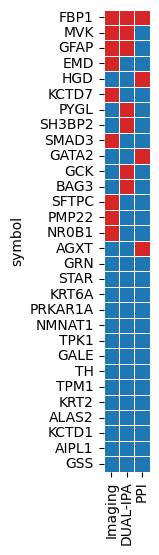

Hit rate: 53.333%


In [13]:
overlapped_genes = list(set(imaging_gene.index).intersection(set(dual_ipa_gene.index)).intersection(set(ppi_gene.index)))

# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes.loc[overlapped_genes,["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold_dualipa": "DUAL-IPA",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

# Sort by row sum (total number of assays passed) - largest to smallest
# First calculate row sums treating NaN as 0 for sorting purposes
row_sums = heatmap_data.fillna(0).sum(axis=1)
sort_order = row_sums.sort_values(ascending=False).index
heatmap_data = heatmap_data.loc[sort_order]

# Create mask AFTER sorting
mask = heatmap_data.isna()

# Convert boolean to int, but keep NaN as NaN initially
heatmap_data_filled = heatmap_data.astype(float)  # Keep as float to preserve NaN

# Create custom colormap: blue for False (0), red for True (1)
colors = ['#1f77b4', '#d62728']  # blue, red
custom_cmap = ListedColormap(colors)

# Set the bad color (for masked values) to light grey
custom_cmap.set_bad(color='lightgrey')

fig, ax = plt.subplots(1,1,figsize=(6,6))
sns.heatmap(heatmap_data_filled, 
            # mask=panel1_mask,
            cmap=custom_cmap, 
            square=True,
            cbar=False,
            linewidths=0.5,
            linecolor='white',
            ax=ax,
            yticklabels=True,
            vmin=0, vmax=1
)
plt.show()

hit_rate = heatmap_data_filled.loc[heatmap_data_filled.sum(axis=1) > 0,:].shape[0] / heatmap_data_filled.shape[0]
print(f"Hit rate: {hit_rate*100:.3f}%")

In [14]:
# # Prepare data for heatmap - handle NaN values properly
# heatmap_data = merged_genes[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].rename(
#     {
#         "Passes_Threshold_imaging": "Imaging",
#         "Passes_Threshold_dualipa": "DUAL-IPA",
#         "Passes_Threshold": "PPI"
#     }, axis=1
# ).copy()

# # Sort by row sum (total number of assays passed) - largest to smallest
# # First calculate row sums treating NaN as 0 for sorting purposes
# row_sums = heatmap_data.fillna(0).sum(axis=1)
# sort_order = row_sums.sort_values(ascending=False).index
# heatmap_data = heatmap_data.loc[sort_order]

# # Create mask AFTER sorting
# mask = heatmap_data.isna()

# # Convert boolean to int, but keep NaN as NaN initially
# heatmap_data_filled = heatmap_data.astype(float)  # Keep as float to preserve NaN

# # Create custom colormap: blue for False (0), red for True (1)
# colors = ['#1f77b4', '#d62728']  # blue, red
# custom_cmap = ListedColormap(colors)

# # Set the bad color (for masked values) to light grey
# custom_cmap.set_bad(color='lightgrey')

# # Split into 3 horizontal panels with ~50 genes each
# n_genes = len(heatmap_data_filled)
# genes_per_panel = 52
# n_panels = 3
# genes_panel1 = min(genes_per_panel, n_genes)
# genes_panel2 = min(genes_per_panel, max(0, n_genes - genes_panel1))
# genes_panel3 = max(0, n_genes - genes_panel1 - genes_panel2)

# # Use gridspec for better control over spacing
# from matplotlib.gridspec import GridSpec
# fig = plt.figure(figsize=(18, 15))
# gs = GridSpec(1, 3, width_ratios=[1, 1, .67], wspace=-.94)  # Extra width for panel 3 colorbar
# axes = [fig.add_subplot(gs[0, i]) for i in range(3)]

# # Panel 1: First ~50 genes
# if genes_panel1 > 0:
#     panel1_data = heatmap_data_filled.iloc[:genes_panel1]
#     panel1_mask = mask.iloc[:genes_panel1]
#     sns.heatmap(panel1_data, 
#                 mask=panel1_mask,
#                 cmap=custom_cmap, 
#                 square=True,
#                 cbar=False,
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[0],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[0].set_ylabel('Gene Symbol', fontsize=10)
#     axes[0].set_xlabel('Assay Type')
#     axes[0].set_title(f'Functional Assay\nDistinguishable Genes')
#     axes[0].tick_params(axis='y', labelsize=9)

# # Panel 2: Next ~50 genes
# if genes_panel2 > 0:
#     panel2_data = heatmap_data_filled.iloc[genes_panel1:genes_panel1+genes_panel2]
#     panel2_mask = mask.iloc[genes_panel1:genes_panel1+genes_panel2]
    
#     sns.heatmap(panel2_data, 
#                 mask=panel2_mask,
#                 cmap=custom_cmap, 
#                 square=True,
#                 cbar=False,
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[1],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[1].set_ylabel('')
#     axes[1].set_xlabel('Assay Type')
#     axes[1].set_title(f'Functional Assay\nNon-Distinguishable Genes')
#     axes[1].tick_params(axis='y', labelsize=9)
# else:
#     axes[1].set_visible(False)

# # Panel 3: Remaining genes
# if genes_panel3 > 0:
#     panel3_data = heatmap_data_filled.iloc[genes_panel1+genes_panel2:]
#     panel3_mask = mask.iloc[genes_panel1+genes_panel2:]
    
#     sns.heatmap(panel3_data, 
#                 mask=panel3_mask,
#                 cmap=custom_cmap, 
#                 square=True,
#                 cbar_kws={'ticks': [0, 1], 'label': 'Distinguish\nPathogenic vs Benign', 'shrink': 0.3, 'format': FixedFormatter(['False', 'True'])},
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[2],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[2].set_ylabel('')
#     axes[2].set_xlabel('Assay Type')
#     axes[2].set_title(f'Functional Assay\nNon-Distinguishable Genes')
#     axes[2].tick_params(axis='y', labelsize=9)
# else:
#     axes[2].set_visible(False)

# # plt.suptitle('Gene Performance Across Assays (Sorted by Total Passes)\n(Red=Pass, Blue=Fail, Grey=No Data)', y=0.95)
# plt.show()
# # merged_genes

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,AGXT,1_Pathogenic,55,16,29.090909,59
1,AGXT,2_Benign,4,1,25.000000,59
2,STXBP1,1_Pathogenic,22,20,90.909091,24
3,STXBP1,2_Benign,2,0,0.000000,24
4,DCX,1_Pathogenic,23,4,17.391304,23
...,...,...,...,...,...,...
108,EIF2B4,2_Benign,1,0,0.000000,1
109,CRADD,2_Benign,1,0,0.000000,1
110,CORO1A,1_Pathogenic,1,0,0.000000,1
111,ASNS,1_Pathogenic,1,1,100.000000,1


Gene Classification Summary (n=86 genes):
  Low_Sensitivity: 48 genes
  High_Discriminatory: 37 genes
  High_False_Positive: 1 genes

Genes passing threshold: 37/86 (43.0%)
Genes passing criteria (benign < 0.001% AND pathogenic > 0%): 37
Genes: ['AMPD2', 'ASNS', 'BAG3', 'CDC73', 'CHN1', 'CLDN19', 'COMP', 'DCX', 'FBP1', 'FXN', 'GAMT', 'GCK', 'GFAP', 'HBD', 'HGD', 'KCNJ2', 'KLHL3', 'KRT2', 'KRT4', 'MID1', 'MVK', 'NAA10', 'NEUROG3', 'NMNAT1', 'NT5C3A', 'ORC6', 'PHYH', 'PHYKPL', 'PRPF31', 'PYGL', 'SFTPC', 'SH3BP2', 'SMAD3', 'SMARCB1', 'STAR', 'STXBP1', 'TAT']


,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,F9,1_Pathogenic,35,4,11.428571,46
1,F9,2_Benign,11,0,0.000000,46
2,BRCA1,1_Pathogenic,22,4,18.181818,36
3,BRCA1,2_Benign,14,0,0.000000,36
4,AGXT,1_Pathogenic,14,2,14.285714,20
...,...,...,...,...,...,...
143,CLDN19,2_Benign,1,0,0.000000,1
144,CFP,1_Pathogenic,1,0,0.000000,1
145,CCBE1,1_Pathogenic,1,0,0.000000,1
146,AMPD2,1_Pathogenic,1,0,0.000000,1


Gene Classification Summary (n=114 genes):
  Low_Sensitivity: 76 genes
  High_Discriminatory: 35 genes
  High_False_Positive: 2 genes
  Low_Discriminatory: 1 genes

Genes passing threshold: 35/114 (30.7%)
Genes passing criteria (benign < 0.001% AND pathogenic > 0%): 35
Genes: ['AGXT', 'AP2S1', 'BFSP2', 'BRCA1', 'BRIP1', 'CTCF', 'DCX', 'DES', 'EMD', 'F9', 'FBP1', 'FH', 'FXN', 'GFAP', 'HPRT1', 'IL36RN', 'KCTD7', 'KRAS', 'LMNA', 'MLH1', 'MSRB3', 'MVK', 'NR0B1', 'NT5C3A', 'PLP1', 'PMP22', 'RAF1', 'RHO', 'RP2', 'SDHD', 'SFTPA2', 'SFTPC', 'SHOC2', 'SMAD3', 'ZC4H2']


,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,AGXT,1_Pathogenic,12,6,50.000000,18
1,AGXT,2_Benign,6,0,0.000000,18
2,STXBP1,1_Pathogenic,14,11,78.571429,16
3,STXBP1,2_Benign,2,0,0.000000,16
4,TTR,1_Pathogenic,14,0,0.000000,14
...,...,...,...,...,...,...
70,GATA2,1_Pathogenic,1,1,100.000000,1
71,FA2H,1_Pathogenic,1,0,0.000000,1
72,EZH2,1_Pathogenic,1,0,0.000000,1
73,COQ8A,1_Pathogenic,1,0,0.000000,1


Gene Classification Summary (n=63 genes):
  Low_Sensitivity: 48 genes
  High_Discriminatory: 15 genes

Genes passing threshold: 15/63 (23.8%)
Genes passing criteria (benign < 0.001% AND pathogenic > 0%): 15
Genes: ['AGXT', 'ASNS', 'FBP1', 'GATA2', 'HGD', 'HPRT1', 'IL36RN', 'KCNJ2', 'KRT6A', 'MLH1', 'PCCA', 'PLP1', 'STXBP1', 'TPM1', 'VHL']
Imaging genes: 114
Dual-IPA genes: 86
PPI genes: 63
Merged genes (union): 154
Genes in ALL three assays: 30


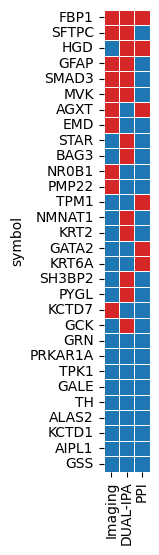

Hit rate: 70.000%


In [15]:
dual_ipa_gene_any_path = explained_gene_per_assay(dualipa.with_columns(
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
).filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
), benign_thres=1e-3, pathogenic_thres=0)
imaging_gene_any_path = explained_gene_per_assay(imaging.with_columns(
    pl.when(pl.col("Altered_95th_perc_both_batches_GFP"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
).filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
), benign_thres=1e-3, pathogenic_thres=0)
ppi_gene_any_path = explained_gene_per_assay(ppi.with_columns(
    pl.when(pl.col("ppi_hit"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
).filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
), benign_thres=1e-3, pathogenic_thres=0)

# Merge imaging_gene and dual_ipa_gene based on union of their indices
merged_genes_any_path = imaging_gene_any_path.join(dual_ipa_gene_any_path, how='outer', lsuffix='_imaging', rsuffix='_dualipa')
merged_genes_any_path = merged_genes_any_path.join(ppi_gene_any_path, how='outer', rsuffix='_ppi')

# Display the merged result
print(f"Imaging genes: {len(imaging_gene_any_path)}")
print(f"Dual-IPA genes: {len(dual_ipa_gene_any_path)}")
print(f"PPI genes: {len(ppi_gene_any_path)}")
print(f"Merged genes (union): {len(merged_genes_any_path)}")
print(f"Genes in ALL three assays: {len(set(imaging_gene_any_path.index).intersection(set(dual_ipa_gene_any_path.index)).intersection(set(ppi_gene_any_path.index)))}")

merged_genes_any_path[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]]
merged_genes_any_path["true_count"] = merged_genes_any_path[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].sum(axis=1)
merged_genes_any_path["non_null_count"] = merged_genes_any_path[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].notna().sum(axis=1)
merged_genes_any_path = merged_genes_any_path.sort_values(by=["non_null_count","true_count"], ascending=[False,False])

overlapped_genes_any_path = list(set(imaging_gene_any_path.index).intersection(set(dual_ipa_gene_any_path.index)).intersection(set(ppi_gene_any_path.index)))
# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes_any_path.loc[overlapped_genes_any_path,["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold_dualipa": "DUAL-IPA",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

# Sort by row sum (total number of assays passed) - largest to smallest
# First calculate row sums treating NaN as 0 for sorting purposes
row_sums = heatmap_data.fillna(0).sum(axis=1)
sort_order = row_sums.sort_values(ascending=False).index
heatmap_data = heatmap_data.loc[sort_order]

# Create mask AFTER sorting
mask = heatmap_data.isna()

# Convert boolean to int, but keep NaN as NaN initially
heatmap_data_filled = heatmap_data.astype(float)  # Keep as float to preserve NaN

# Create custom colormap: blue for False (0), red for True (1)
colors = ['#1f77b4', '#d62728']  # blue, red
custom_cmap = ListedColormap(colors)

# Set the bad color (for masked values) to light grey
custom_cmap.set_bad(color='lightgrey')

fig, ax = plt.subplots(1,1,figsize=(6,6))
sns.heatmap(heatmap_data_filled, 
            # mask=panel1_mask,
            cmap=custom_cmap, 
            square=True,
            cbar=False,
            linewidths=0.5,
            linecolor='white',
            ax=ax,
            yticklabels=True,
            vmin=0, vmax=1
)
plt.show()

hit_rate = heatmap_data_filled.loc[heatmap_data_filled.sum(axis=1) > 0,:].shape[0] / heatmap_data_filled.shape[0]
print(f"Hit rate: {hit_rate*100:.3f}%")

<Figure size 640x480 with 0 Axes>

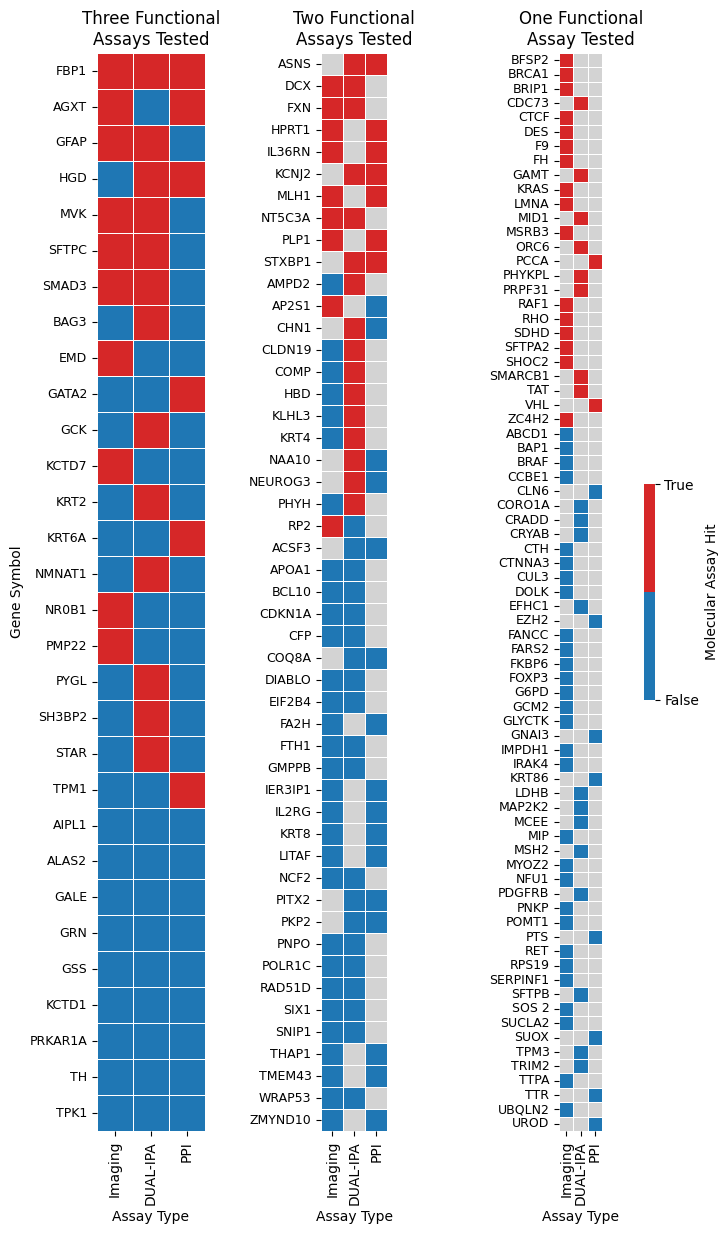

In [16]:
plt.clf()
# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes_any_path.loc[:,["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold_dualipa": "DUAL-IPA",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

# Sort by row sum (total number of assays passed) - largest to smallest
# First calculate row sums treating NaN as 0 for sorting purposes
row_sums = heatmap_data.fillna(0).sum(axis=1)
sort_order = row_sums.sort_values(ascending=False).index
heatmap_data = heatmap_data.loc[sort_order]

# Create mask AFTER sorting
mask = heatmap_data.isna()
# Convert boolean to int, but keep NaN as NaN initially
heatmap_data_filled = heatmap_data.astype(float)  # Keep as float to preserve NaN

genes_panel1 = merged_genes_any_path[merged_genes_any_path["non_null_count"]==3].index
genes_panel2 = merged_genes_any_path[merged_genes_any_path["non_null_count"]==2].index
genes_panel3 = merged_genes_any_path[merged_genes_any_path["non_null_count"]==1].index

# Use gridspec for better control over spacing
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(16, 14))
gs = GridSpec(1, 3, width_ratios=[1, 1, .67], wspace=-.94)  # Extra width for panel 3 colorbar
axes = [fig.add_subplot(gs[0, i]) for i in range(3)]

# Panel 1: First ~50 genes
if len(genes_panel1) > 0:
    panel1_data = heatmap_data_filled.loc[genes_panel1,]
    panel1_mask = mask.loc[genes_panel1,]
    sns.heatmap(panel1_data, 
                mask=panel1_mask,
                cmap=custom_cmap, 
                square=True,
                cbar=False,
                linewidths=0.5,
                linecolor='white',
                ax=axes[0],
                yticklabels=True,
                vmin=0, vmax=1
                )
    axes[0].set_ylabel('Gene Symbol', fontsize=10)
    axes[0].set_xlabel('Assay Type')
    axes[0].set_title(f'Three Functional\nAssays Tested')
    axes[0].tick_params(axis='y', labelsize=9)

# Panel 2: Next ~50 genes
if len(genes_panel2) > 0:
    panel2_data = heatmap_data_filled.loc[genes_panel2,]
    panel2_mask = mask.loc[genes_panel2,]
    
    sns.heatmap(panel2_data, 
                mask=panel2_mask,
                cmap=custom_cmap, 
                square=True,
                cbar=False,
                linewidths=0.5,
                linecolor='white',
                ax=axes[1],
                yticklabels=True,
                vmin=0, vmax=1
                )
    axes[1].set_ylabel('')
    axes[1].set_xlabel('Assay Type')
    axes[1].set_title(f'Two Functional\nAssays Tested')
    axes[1].tick_params(axis='y', labelsize=9)
else:
    axes[1].set_visible(False)

# Panel 3: Remaining genes
if len(genes_panel3) > 0:
    panel3_data = heatmap_data_filled.loc[genes_panel3,]
    panel3_mask = mask.loc[genes_panel3,]
    
    sns.heatmap(panel3_data, 
                mask=panel3_mask,
                cmap=custom_cmap, 
                square=True,
                cbar_kws={'ticks': [0, 1], 'label': 'Molecular Assay Hit', 'shrink': 0.2, 'format': FixedFormatter(['False', 'True'])},
                linewidths=0.5,
                linecolor='white',
                ax=axes[2],
                yticklabels=True,
                vmin=0, vmax=1
                )
    axes[2].set_ylabel('')
    axes[2].set_xlabel('Assay Type')
    axes[2].set_title(f'One Functional\nAssay Tested')
    axes[2].tick_params(axis='y', labelsize=9)
else:
    axes[2].set_visible(False)

# plt.suptitle('Gene Performance Across Assays (Sorted by Total Passes)\n(Red=Pass, Blue=Fail, Grey=No Data)', y=0.95)
plt.show()
# merged_genes

In [ ]:
merged_genes_any_path[merged_genes_any_path]"non_null_count")==3)

,1_Pathogenic_imaging,2_Benign_imaging,Classification_imaging,Passes_Threshold_imaging,total_counts_imaging,total_counts_all_imaging,hit_counts_imaging,fisher_oddsratio_imaging,fisher_pval_imaging,pathogenic_hit_imaging,...,fisher_oddsratio,fisher_pval,pathogenic_hit,pathogenic_total,pathogenic_nonhit,benign_hit,benign_total,benign_nonhit,true_count,non_null_count
symbol,,,,,,,,,,,,,,,,,,,,,
FBP1,75.000000,0.0,High_Discriminatory,True,4.0,7.0,3.0,inf,0.142857,3.0,...,NaN,1.000000,2.0,2.0,0.0,0.0,0.0,0.0,3,3
AGXT,14.285714,0.0,High_Discriminatory,True,14.0,20.0,2.0,inf,1.000000,2.0,...,inf,0.053706,6.0,12.0,6.0,0.0,6.0,6.0,2,3
GFAP,85.714286,0.0,High_Discriminatory,True,7.0,8.0,6.0,inf,0.250000,6.0,...,NaN,1.000000,0.0,6.0,6.0,0.0,0.0,0.0,2,3
HGD,0.000000,0.0,Low_Sensitivity,False,1.0,1.0,0.0,NaN,1.000000,0.0,...,NaN,1.000000,5.0,7.0,2.0,0.0,0.0,0.0,2,3
MVK,25.000000,0.0,High_Discriminatory,True,8.0,8.0,2.0,NaN,1.000000,2.0,...,NaN,1.000000,0.0,6.0,6.0,0.0,1.0,1.0,2,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TRIM2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1
TTPA,0.000000,0.0,Low_Sensitivity,False,2.0,2.0,0.0,NaN,1.000000,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1
TTR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.000000,0.0,14.0,14.0,0.0,0.0,0.0,0,1


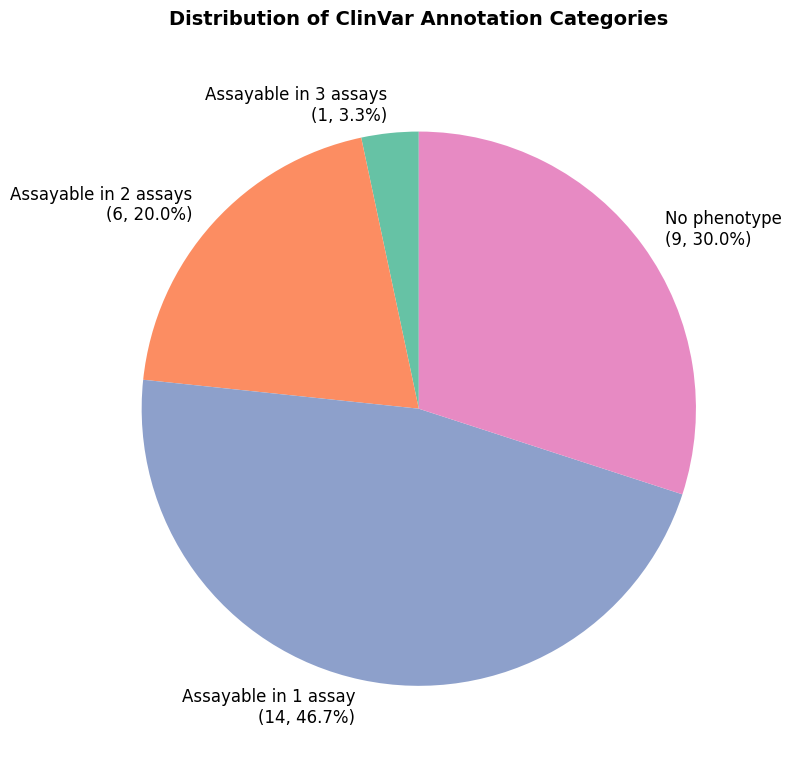

ClinVar Annotation Distribution:
Assayable in 3 assays: 1 variants (3.3%)
Assayable in 2 assays: 6 variants (20.0%)
Assayable in 1 assay: 14 variants (46.7%)
No phenotype: 9 variants (30.0%)

Total variants: 30


In [28]:
# Create pie chart for ClinVar annotation categories
merged_genes_any_path_pl = pl.DataFrame(merged_genes_any_path).with_columns(
    pl.when(pl.col("true_count")==0)
    .then(pl.lit("No phenotype"))
    .when(pl.col("true_count")==1)
    .then(pl.lit("Assayable in 1 assay"))
    .when(pl.col("true_count")==2)
    .then(pl.lit("Assayable in 2 assays"))
    .otherwise(pl.lit("Assayable in 3 assays"))
    .alias("Assayable")
).filter(
    pl.col("non_null_count")==3
)
# Get the category counts from the merged data
summary_clin_var_counts = merged_genes_any_path_pl.group_by("Assayable").len() #.sort("clinvar_clnsig_clean")#.sort("len", descending=True)
summary_clin_var_counts = merged_genes_any_path_pl.group_by("Assayable").len().to_pandas()
category_order = ["Assayable in 3 assays", "Assayable in 2 assays", "Assayable in 1 assay", "No phenotype"]
summary_clin_var_counts['Assayable'] = pd.Categorical(summary_clin_var_counts['Assayable'], categories=category_order, ordered=True)

# Convert to pandas for easier plotting
pie_data = summary_clin_var_counts.sort_values('Assayable')
pie_data = pie_data.dropna()  # Remove any null values

# Calculate percentages
total_count = pie_data["len"].sum()
pie_data["percentage"] = (pie_data["len"] / total_count * 100).round(1)

# Create labels with counts and percentages
labels = [f"{cat}\n({count}, {pct}%)" 
          for cat, count, pct in zip(pie_data["Assayable"], 
                                   pie_data["len"], 
                                   pie_data["percentage"])]

# Use a color palette that matches the boxenplot
# colors = list(palette_dict["clinvar_clnsig_clean"].values())
# colors[1], colors[3] = colors[3], colors[1]  # Swap colors to match the order in pie chart
# Create pie chart
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
wedges, texts, autotexts = ax.pie(pie_data["len"], 
                                  labels=labels, 
                                  colors=sns.color_palette("Set2"),
                                  autopct="",  # We're including percentages in labels
                                  startangle=90,
                                  textprops={'fontsize': 12})

ax.set_title("Distribution of ClinVar Annotation Categories", fontsize=14, fontweight='bold', pad=20)

# Equal aspect ratio ensures that pie is drawn as a circle
ax.axis('equal')

# # Add a legend
# ax.legend(wedges, [f"{cat} (n={count})" for cat, count in zip(pie_data["clinvar_clnsig_clean"], pie_data["len"])],
#           title="Categories",
#           loc="center left",
#           bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.show()

# Print summary statistics
print("ClinVar Annotation Distribution:")
print("=" * 40)
for _, row in pie_data.iterrows():
    print(f"{row['Assayable']}: {row['len']} variants ({row['percentage']}%)")
print(f"\nTotal variants: {total_count}")

### 3.1 Gene alleles profiled by ALL 3 assays

In [26]:
meta_cols = ["symbol", "gene_variant", "ensembl_gene_id", "spdi", "orf_id", "mut_id", 
             "nt_change", "aa_change", "clinvar_clnsig_clean", "clinvar_clnsig_clean_pp_strict", "gnomAD4.1_joint_AF", "StarStatus",
             "inheritance_pattern", "AlphaMissense_score", "AlphaMissense_rankscore", "AlphaMissense_pred", 
             "ESM1b_score", "ESM1b_rankscore", "ESM1b_pred",
             "plddt_f32", "rsa_f32", "RSA_Category", "pLDDT_Category"]
dualipa_cols = ["dualipa_abun_score", "dualipa_abun_change", "dualipa_abun_chg_dir"]
img_cols = ["AUROC_Mean_GFP", "Altered_95th_perc_both_batches_GFP"] ## "AUROC_Mean_DNA", "Altered_95th_perc_both_batches_DNA"
ppi_cols = ["normalized_euclid_distance_normalized", "ppi_hit"]

al_dual_img_ppi_key_cols = al_dual_img_ppi.select(
    pl.col(meta_cols + dualipa_cols + img_cols + ppi_cols)
)

### 3.2 Gene Alleles Profiled by AT LEAST ONE assay

In [27]:
alleles_prof_one_assay = al_dual_img_ppi_key_cols.filter(
    ~pl.all_horizontal([pl.col(col).is_null() for col in dualipa_cols+img_cols+ppi_cols])
).unique(subset="gene_variant")
alleles_prof_one_assay

# alleles_prof_one_assay.write_csv(
#     "../3_outputs/all_gene_alleles_profiled_by_any_assay.csv"
# )

symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,clinvar_clnsig_clean_pp_strict,gnomAD4.1_joint_AF,StarStatus,inheritance_pattern,AlphaMissense_score,AlphaMissense_rankscore,AlphaMissense_pred,ESM1b_score,ESM1b_rankscore,ESM1b_pred,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,normalized_euclid_distance_normalized,ppi_hit
str,str,str,str,i64,i64,str,str,str,str,str,f64,str,str,str,str,str,str,str,f64,f64,str,str,f64,str,str,f64,bool,f64,bool
"""F9""","""F9_Cys170Tyr""","""ENSG00000101981""","""NC_000023.11:139548480:G:A""",52861,24671,"""509G>A""","""Cys170Tyr""","""Pathogenic""","""Pathogenic""",""".""",1.0,null,"""0.9818""","""0.94596""","""P""","""-14.847""","""0.95493""","""D""",95.58,4.4444447,"""<10""",""">90""",null,null,null,0.94194,false,null,null
"""SMAD3""","""SMAD3_Asp408His""","""ENSG00000166949""","""NC_000015.10:67190480:G:C""",11805,2180,"""1222G>C""","""Asp408His""","""Conflicting""","""Conflicting""",""".""",1.0,null,"""0.9997""","""0.99584""","""P""","""-14.976""","""0.95988""","""D""",93.11,59.5092,"""10-90""",""">90""",-1.198291,"""Uncertain""","""Decrease""",0.728582,false,null,null
"""NT5C3A""","""NT5C3A_Phe31Leu""","""ENSG00000122643""","""NC_000007.14:33062615:A:G""",14396,900163,"""91T>C""","""Phe31Leu""","""Benign""","""Likely benign""","""1.943120e-02""",2.0,"""autosomal recessive""","""0.5171""","""0.65296""","""A""",""".""",""".""",""".""",null,null,"""NaN""","""NaN""",-1.855526,"""Uncertain""","""Decrease""",null,null,null,null
"""SMAD3""","""SMAD3_Ile170Val""","""ENSG00000166949""","""NC_000015.10:67165360:A:G""",11805,2134,"""508A>G""","""Ile170Val""","""Benign""","""Likely benign""","""4.907130e-02""",2.0,"""autosomal dominant""","""0.0715""","""0.18813""","""B""","""-8.829""","""0.68071""","""D""",36.65,100.0,"""$\geqslant$90""","""$\leqslant$50""",0.04168,"""N""","""Increase""",0.715565,false,0.023896,false
"""KCNJ2""","""KCNJ2_Ala70Ser""","""ENSG00000123700""","""NC_000017.11:70175247:G:T""",100016069,2607,"""208G>T""","""Ala70Ser""","""Conflicting""","""Conflicting""","""4.150990e-05""",1.0,"""autosomal dominant""","""0.0791""","""0.09233""","""LB""","""-4.095""","""0.25240""","""T""",88.97,88.679245,"""10-90""","""70-90""",-3.31566,"""Y""","""Decrease""",null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""PNPO""","""PNPO_Arg229Trp""","""ENSG00000108439""","""NC_000017.11:47946681:C:T""",4515,8612,"""685C>T""","""Arg229Trp""","""Pathogenic""","""Likely pathogenic""","""6.814660e-06""",2.0,"""autosomal recessive""","""0.9303""","""0.85005""","""P""","""-13.799""","""0.92400""","""D""",98.42,19.758064,"""10-90""",""">90""",-0.805356,"""Uncertain""","""Decrease""",null,null,null,null
"""EFHC1""","""EFHC1_Ala394Ser""","""ENSG00000096093""","""NC_000006.12:52469375:G:T""",7866,14147,"""1180G>T""","""Ala394Ser""","""Others""","""Others""",null,null,null,null,null,null,null,null,null,null,null,"""NaN""","""NaN""",0.780596,"""N""","""Increase""",null,null,null,null
"""MLH1""","""MLH1_Leu73Arg""","""ENSG00000076242""","""NC_000003.12:37000965:T:G""",2713,200818,"""218T>G""","""Leu73Arg""","""Pathogenic""","""Likely pathogenic""",""".""",2.0,"""multiple""","""0.9326""","""0.85203""","""P""","""-13.257""","""0.90414""","""D""",93.79,0.0,"""<10""",""">90""",null,null,null,null,null,0.583223,false


In [29]:
# palette_dict = {
#     "clinvar_clnsig_clean":{
#         '1_Pathogenic': "#CA7682",
#         '2_Benign': "#1D7AAB",
#         '3_Conflicting': "#E6B1B8", #"grey",
#         '4_VUS': "#A0A0A0",
#         '5_Others': "#A0A0A0"
#         # '6_No_ClinVar'
#     }
# }

# fig, axes = plt.subplots(1,3,figsize=(18,5))
# plot_cat_count_perc(
#     alleles_prof_one_assay,
#     "clinvar_clnsig_clean",
#     title="ClinVar",
#     ax=axes[0],
#     palette=palette_dict["clinvar_clnsig_clean"]
# )
# # axes[0].legend(loc="lower right")
# axes[0].set_title("Genetic Variant ClinVar Info")

# plot_cat_count_perc(
#     alleles_prof_one_assay.unique("symbol"),
#     "inheritance_pattern",
#     title="Inheritance",
#     ax=axes[1],
# )
# axes[1].set_title("Gene-level Inheritance Pattern")

# plot_cat_count_perc(
#     alleles_prof_one_assay,
#     "inheritance_pattern",
#     title="Inheritance",
#     ax=axes[2],
# )
# axes[2].set_title("Variant-level Inheritance Pattern")

# plt.suptitle(f"{alleles_prof_one_assay.unique('gene_variant').shape[0]} Variants from {alleles_prof_one_assay.unique('symbol').shape[0]} Genes Profiled by Any Functional Assay", y=.97, fontsize=14)
# plt.subplots_adjust(wspace=.6)
# plt.show()

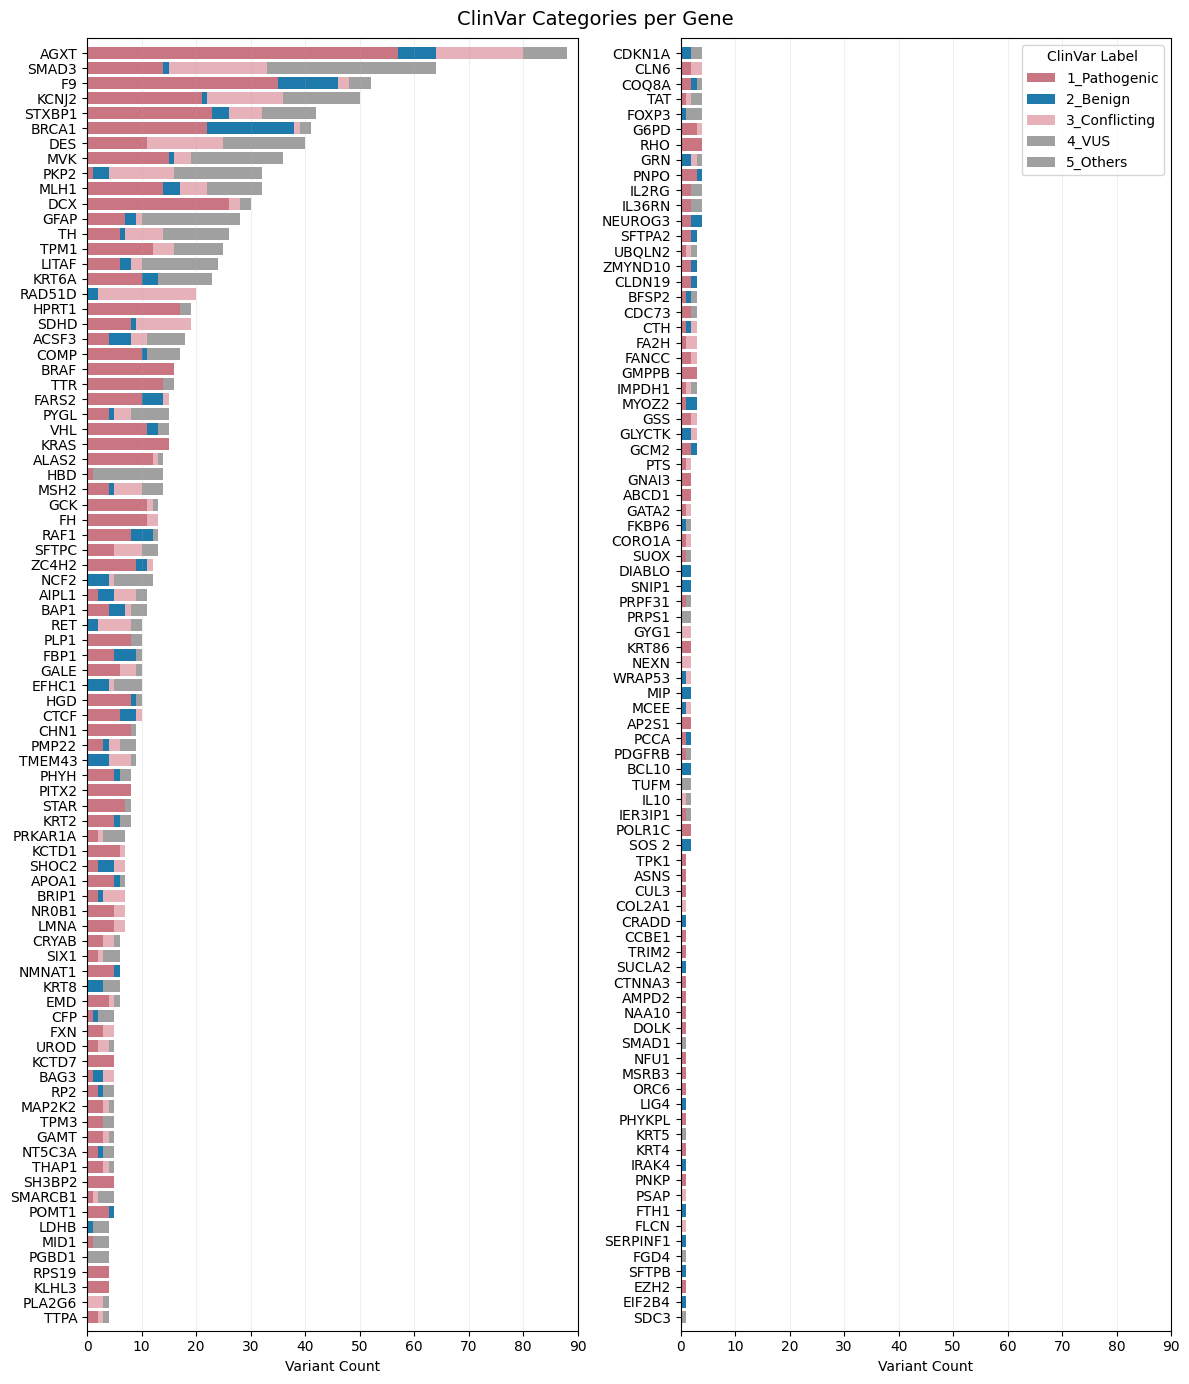

In [23]:
# 2. Count per (gene, category)
df = alleles_prof_one_assay.to_pandas() ## drop_nulls("clinvar_clnsig_clean").

top_num = int(np.ceil(alleles_prof_one_assay.unique("symbol").shape[0] / 2))
counts = (
    df.groupby(["symbol", "clinvar_clnsig_clean"])
    .size()
    .reset_index(name="count")
)
# 3. Pivot
pivot = counts.pivot(index="symbol", columns="clinvar_clnsig_clean", values="count").fillna(0)

# Add total count column and sort by it (descending)
pivot["total_count"] = pivot.sum(axis=1)
pivot_top = pivot.sort_values("total_count", ascending=False).head(top_num)
pivot_top = pivot_top.drop(columns=["total_count"])
# category_order = sorted(pivot_top["clinvar_clnsig_clean"].unique())

# # 4. Ensure category order
# for cat in category_order:
#     if cat not in pivot_top.columns:
#         pivot_top[cat] = 0
# pivot_top = pivot_top[category_order]

# 5. Plotting
fig, axes = plt.subplots(1,2, figsize=(12, 14))
# Get Set2 colors
bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean"].items():
    axes[0].barh(pivot_top.index, pivot_top[cat], 
            left=bottom, label=cat, color=color)
    bottom = pivot_top[cat] if bottom is None else bottom + pivot_top[cat]
    
# Axis formatting
axes[0].set_xlabel("Variant Count")
axes[0].set_xlim(None, 90)
axes[0].set_ylim(-1, pivot_top.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[0].set_title(f"ClinVar Categories per Gene (Top {top_num} with Most Variants)", fontsize=14)
axes[0].invert_yaxis()
axes[0].grid(alpha=.2, axis="x")

# ax.legend(title="ClinVar Label", fontsize=9, title_fontsize=10, loc="lower right")
# plt.tight_layout()
# plt.show()

pivot_bot = pivot.sort_values("total_count", ascending=False).iloc[top_num:,].copy()
pivot_bot = pivot_bot.drop(columns=["total_count"])

# 4. Ensure category order
# for cat in category_order:
#     if cat not in pivot_bot.columns:
#         pivot_bot[cat] = 0
# pivot_bot = pivot_bot[category_order]

bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean"].items():
    axes[1].barh(pivot_bot.index, pivot_bot[cat], left=bottom, label=cat, color=color)
    bottom = pivot_bot[cat] if bottom is None else bottom + pivot_bot[cat]
    
# Axis formatting
axes[1].set_xlabel("Variant Count")
axes[1].set_xlim(None, 90)
axes[1].set_ylim(-1, pivot_bot.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[1].set_title(f"ClinVar Categories per Gene ({top_num} After)", fontsize=14)
axes[1].invert_yaxis()
axes[1].legend(title="ClinVar Label", fontsize=10, title_fontsize=10, loc="upper right")
axes[1].grid(alpha=.2, axis="x")
plt.suptitle(f"ClinVar Categories per Gene", fontsize=14, y=.985)
plt.tight_layout()
plt.show()

In [30]:
alleles_prof_one_assay = alleles_prof_one_assay.with_columns(
    pl.when((pl.col("dualipa_abun_change")=="Y") | (pl.col("Altered_95th_perc_both_batches_GFP")) | (pl.col("ppi_hit")))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("any_assay_hit"),
    pl.col("gene_variant").alias("gene_allele")
)

In [31]:
# # Create pie chart for ClinVar annotation categories
# fig, ax = plt.subplots(1, 1, figsize=(8, 8))

# # Get the category counts from the merged data
# summary_clin_var_counts = alleles_prof_one_assay.group_by("clinvar_clnsig_clean").len() #.sort("clinvar_clnsig_clean")#.sort("len", descending=True)
# summary_clin_var_counts = alleles_prof_one_assay.group_by("clinvar_clnsig_clean").len().to_pandas()
# category_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS", "5_Others"]
# summary_clin_var_counts['clinvar_clnsig_clean'] = pd.Categorical(summary_clin_var_counts['clinvar_clnsig_clean'], categories=category_order, ordered=True)

# # Convert to pandas for easier plotting
# pie_data = summary_clin_var_counts.sort_values('clinvar_clnsig_clean')
# pie_data = pie_data.dropna()  # Remove any null values

# # Calculate percentages
# total_count = pie_data["len"].sum()
# pie_data["percentage"] = (pie_data["len"] / total_count * 100).round(1)

# # Create labels with counts and percentages
# labels = [f"{cat.split('_')[1]}\n({count}, {pct}%)" 
#           for cat, count, pct in zip(pie_data["clinvar_clnsig_clean"], 
#                                    pie_data["len"], 
#                                    pie_data["percentage"])]

# # Use a color palette that matches the boxenplot
# colors = list(palette_dict["clinvar_clnsig_clean"].values())
# # colors[1], colors[3] = colors[3], colors[1]  # Swap colors to match the order in pie chart
# # Create pie chart
# wedges, texts, autotexts = ax.pie(pie_data["len"], 
#                                   labels=labels, 
#                                   colors=colors,
#                                   autopct="",  # We're including percentages in labels
#                                   startangle=90,
#                                   textprops={'fontsize': 12})

# ax.set_title("Distribution of ClinVar Annotation Categories", fontsize=14, fontweight='bold', pad=20)

# # Equal aspect ratio ensures that pie is drawn as a circle
# ax.axis('equal')

# # # Add a legend
# # ax.legend(wedges, [f"{cat} (n={count})" for cat, count in zip(pie_data["clinvar_clnsig_clean"], pie_data["len"])],
# #           title="Categories",
# #           loc="center left",
# #           bbox_to_anchor=(1, 0, 0.5, 1))

# plt.tight_layout()
# plt.show()

# # Print summary statistics
# print("ClinVar Annotation Distribution:")
# print("=" * 40)
# for _, row in pie_data.iterrows():
#     print(f"{row['clinvar_clnsig_clean']}: {row['len']} variants ({row['percentage']}%)")
# print(f"\nTotal variants: {total_count}")

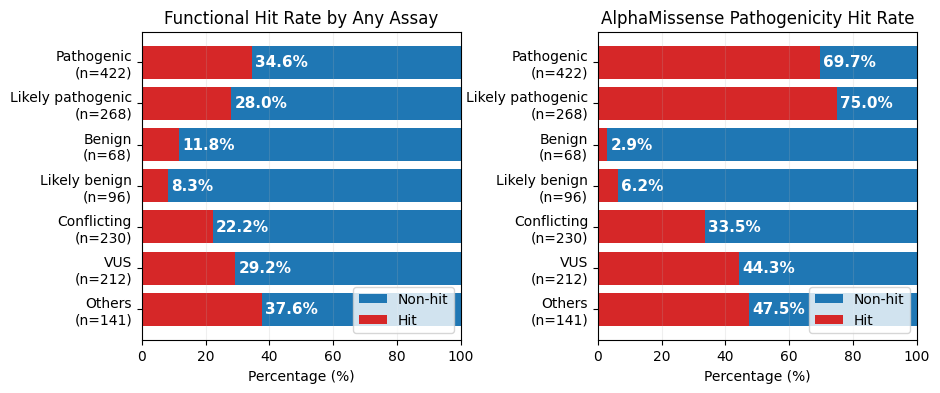

In [38]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
df = alleles_prof_one_assay.unique("gene_variant").to_pandas()
df["AlphaMissense_score"] = df["AlphaMissense_score"].replace(".",np.nan).astype(float)
df["AlphaMissense_pred_call"] = df["AlphaMissense_pred"].astype(str).apply(lambda x : True if "P" in x else False)

plot_assay_hit_by_category_perc(alleles_prof_one_assay.with_columns(
        pl.col("clinvar_clnsig_clean_pp_strict")
            .cast(pl.Enum(clinvar_order_dict["original"]))
    ).sort("clinvar_clnsig_clean_pp_strict"), 
                                "any_assay_hit", "clinvar_clnsig_clean_pp_strict", 
                                f"Functional Hit Rate by Any Assay",
                                ax=axes[0]
)
plot_assay_hit_by_category_perc(
    pl.DataFrame(df).with_columns(
        pl.col("clinvar_clnsig_clean_pp_strict")
            .cast(pl.Enum(clinvar_order_dict["original"]))
    ).sort("clinvar_clnsig_clean_pp_strict"), 
    "AlphaMissense_pred_call", 
    "clinvar_clnsig_clean_pp_strict", 
    f"AlphaMissense Pathogenicity Hit Rate", 
    ax=axes[1]
)
plt.subplots_adjust(wspace=0.43)
plt.show()

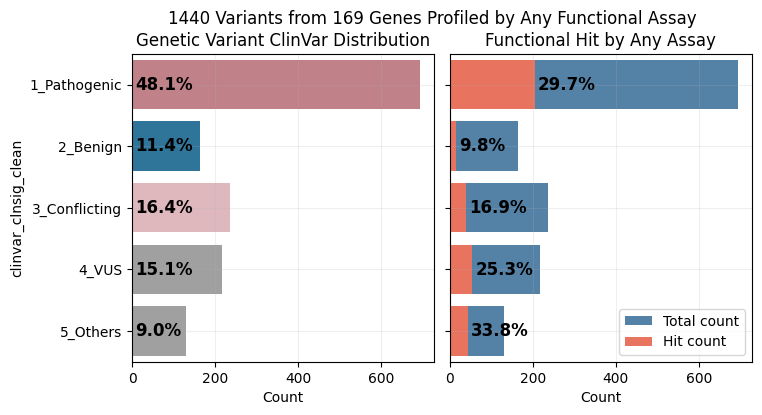

In [38]:
fig, axes = plt.subplots(1,2,figsize=(8,4),sharey=True)
plot_cat_count_perc(
    alleles_prof_one_assay,
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean"]
)
axes[0].set_title("Genetic Variant ClinVar Distribution")
axes[0].set_xlabel("Count")

axes[0].grid(alpha=.2)

plot_assay_hit_by_category(alleles_prof_one_assay, "any_assay_hit", "clinvar_clnsig_clean", f"Functional Hit by Any Assay", ax=axes[1])
axes[1].set_xlabel("Count")

plt.suptitle(f"{alleles_prof_one_assay.unique('gene_variant').shape[0]} Variants from {alleles_prof_one_assay.unique('symbol').shape[0]} Genes Profiled by Any Functional Assay", y=.99, fontsize=12)
plt.subplots_adjust(wspace=.05)
plt.show()

### 3.3 Plot hits

In [ ]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

al_dual_img_ppi_intersect = al_dual_img_ppi.filter(
    pl.col("dualipa_abun_score").is_not_null(),
    pl.col("AUROC_Mean_GFP").is_not_null(),
    pl.col("normalized_euclid_distance").is_not_null()
).unique("gene_variant")

df = al_dual_img_ppi_intersect.select(
    pl.col(["symbol", "gene_variant", "dualipa_abun_change", "Altered_95th_perc_both_batches_GFP", "hit", "clinvar_clnsig_clean"])
).with_columns(
    pl.when(pl.col("dualipa_abun_change")==1)
    .then(pl.lit(1))
    .otherwise(pl.lit(0))
    .alias("DUAL-IPA"),
    pl.col("Altered_95th_perc_both_batches_GFP").cast(pl.Int8).alias("Imaging"),
    pl.col("hit").alias("sqY2H"),
).to_pandas()

# Ensure hit columns are ints
hit_cols = ['DUAL-IPA', 'Imaging', 'sqY2H']
df[hit_cols] = df[hit_cols].astype(int)

# Sort by gene symbol and ClinVar category
df_sorted = df.sort_values(['symbol', 'clinvar_clnsig_clean'])

# Create the hit matrix
matrix = df_sorted.set_index('gene_variant')[hit_cols]

# Row colors for ClinVar categories
lut = palette_dict["clinvar_clnsig_clean"]
row_colors_clinvar = df_sorted['clinvar_clnsig_clean'].map(lut).values

# Split genes into three groups while keeping alleles together
unique_genes = df_sorted['symbol'].unique()
n_genes = len(unique_genes)
split_point1 = n_genes // 3
split_point2 = 2 * n_genes // 3

genes_part1 = unique_genes[:split_point1]
genes_part2 = unique_genes[split_point1:split_point2]
genes_part3 = unique_genes[split_point2:]

# Create three separate datasets
df_part1 = df_sorted[df_sorted['symbol'].isin(genes_part1)]
df_part2 = df_sorted[df_sorted['symbol'].isin(genes_part2)]
df_part3 = df_sorted[df_sorted['symbol'].isin(genes_part3)]

def create_clustermap_part(df_part, part_name, genes_subset):
    # Create matrix for this part
    matrix_part = df_part.set_index('gene_variant')[hit_cols]
    
    # Row colors for ClinVar categories
    row_colors_clinvar_part = df_part['clinvar_clnsig_clean'].map(lut).values
    
    # Row colors for gene symbols (use consistent colors)
    gene_palette = sns.color_palette("tab20", 20) + sns.color_palette("Set1", n_genes-20)
    gene_lut = dict(zip(unique_genes, gene_palette))  # Keep all genes for consistent colors
    row_colors_genes_part = [gene_lut[gene] for gene in df_part['symbol']]
    
    # Combine row colors
    row_colors_part = [row_colors_clinvar_part, row_colors_genes_part]
    
    # Create clustermap
    g = sns.clustermap(
        matrix_part,
        row_cluster=False,
        col_cluster=False,
        cmap=cmap,
        linewidths=0.5,
        row_colors=row_colors_part,
        figsize=(5,12),
        colors_ratio=0.1,  # Increase from default 0.03 to make row colors wider
        cbar_pos=(-0.2, 0.45, 0.05, 0.18),
        cbar_kws={
            "ticks": [0, 1],
            "format": "%d",
            "format": lambda x, pos: "False" if x == 0 else "True",
        },
        dendrogram_ratio=0.01,  # Remove dendrogram space
        yticklabels=1
    )
    
    # Add legend for ClinVar categories
    handles = [Patch(facecolor=color, label=label) for label, color in lut.items()]
    g.ax_heatmap.legend(
        handles=handles,
        title='ClinVar',
        bbox_to_anchor=(-1., 0.35),
        loc='center left',
        frameon=False
    )
    g.ax_heatmap.tick_params(axis='x', rotation=45)
    # g.ax_heatmap.set_yticks(range(len(matrix_part)))
    # g.ax_heatmap.set_yticklabels(matrix_part.index, fontsize=10, va='center')

    # Change colorbar labels
    # g.ax_cbar.set_yticklabels(['False', 'True'])
    
    # plt.suptitle(f'{part_name} (Genes: {", ".join(genes_subset[:5])}{"..." if len(genes_subset) > 5 else ""})', 
    #              y=1., fontsize=14)
    plt.show()

# Create both parts
print(f"Part 1: {len(genes_part1)} genes, {len(df_part1)} variants")
create_clustermap_part(df_part1, "Part 1", genes_part1)

print(f"Part 2: {len(genes_part2)} genes, {len(df_part2)} variants")
create_clustermap_part(df_part2, "Part 2", genes_part2)

print(f"Part 2: {len(genes_part2)} genes, {len(df_part2)} variants")
create_clustermap_part(df_part3, "Part 3", genes_part3)